# NARPS Hypothesis 1: potential gain effect

This experiment tests whether larger potential gains are associated with a positive fMRI response in vmPFC in the equal-indifference group. The fixed inputs are 54 participant-level AO86 gain contrast estimates. The test is one-sided and whole-brain familywise corrected, as specified by the original hypothesis.


## Model and decision rule

At each voxel, estimate a one-sample random-effects *t* statistic across participants. Use participant sign flips and the maximum voxelwise *t* statistic for whole-brain familywise correction (5,000 permutations, fixed seed). Use the common nonzero support of all participant maps to avoid treating out-of-mask zeros as observed estimates. The vmPFC label is an a priori medial anterior ventral prefrontal MNI coordinate zone (x −20..20, y 20..60, z −20..20 mm); it is only used to identify whether corrected whole-brain findings fall in vmPFC.


In [1]:
from pathlib import Path
import json, os, subprocess

ROOT = Path.cwd()
PYTHON = Path("/Users/johnlee/.local/state/stamped-in-practice/narps-neutral-v1/common-environment/.pixi/envs/default/bin/python")


In [2]:
run = subprocess.run(
    [str(PYTHON), str(ROOT / "analysis.py"), "--permutations", "5000", "--seed", "20261016"],
    cwd=ROOT, check=True, capture_output=True, text=True,
    env={**os.environ, "MPLBACKEND": "Agg"},
)
print(run.stdout)


{
  "n_participants": 54,
  "n_excluded": 0,
  "map_checksums_verified": 54,
  "grid_shape": [
    97,
    115,
    81
  ],
  "voxel_size_mm": [
    2.0,
    2.0,
    2.4000000953674316
  ],
  "common_support_voxels": 198029,
  "common_support_volume_ml": 1901.0784755420684,
  "vmPFC_coordinate_box_MNI_mm": {
    "x_min": -20,
    "x_max": 20,
    "y_min": 20,
    "y_max": 60,
    "z_min": -20,
    "z_max": 20
  },
  "vmPFC_voxels": 7043,
  "vmPFC_mean_cope": -0.0004832247591900498,
  "vmPFC_mean_cope_95pct_t_CI": [
    -0.014309229093454605,
    0.013342779575074504
  ],
  "vmPFC_peak_t": 4.1918477635940805,
  "vmPFC_peak_xyz_MNI_mm": [
    -2.0,
    24.0,
    -17.99999761581421
  ],
  "vmPFC_FWE_significant_voxels": 0,
  "whole_brain_peak_t": 6.617173246302241,
  "whole_brain_peak_xyz_MNI_mm": [
    -26.0,
    -102.0,
    -3.599997043609619
  ],
  "whole_brain_peak_p_FWE": 0.0009998000399920016,
  "maxT_critical_t_95pct": 5.396594524383545,
  "whole_brain_FWE_significant_voxels": 24,

In [3]:
results = json.loads((ROOT / "results/results.json").read_text())
{key: results[key] for key in [
    "n_participants", "n_excluded", "common_support_voxels",
    "whole_brain_peak_t", "whole_brain_peak_xyz_MNI_mm", "whole_brain_peak_p_FWE",
    "maxT_critical_t_95pct", "whole_brain_FWE_significant_voxels",
    "vmPFC_mean_cope", "vmPFC_mean_cope_95pct_t_CI",
    "vmPFC_peak_t", "vmPFC_FWE_significant_voxels",
]}


{'n_participants': 54,
 'n_excluded': 0,
 'common_support_voxels': 198029,
 'whole_brain_peak_t': 6.617173246302241,
 'whole_brain_peak_xyz_MNI_mm': [-26.0, -102.0, -3.599997043609619],
 'whole_brain_peak_p_FWE': 0.0009998000399920016,
 'maxT_critical_t_95pct': 5.396594524383545,
 'whole_brain_FWE_significant_voxels': 24,
 'vmPFC_mean_cope': -0.0004832247591900498,
 'vmPFC_mean_cope_95pct_t_CI': [-0.014309229093454605, 0.013342779575074504],
 'vmPFC_peak_t': 4.1918477635940805,
 'vmPFC_FWE_significant_voxels': 0}

## Interpretation

The whole-brain correction is the primary decision. A corrected positive effect elsewhere does not support the vmPFC-specific hypothesis. A vmPFC zone estimate or uncorrected voxel statistic is descriptive and does not replace the whole-brain corrected decision. The supplied maps are contrast parameter estimates, not standardized statistics, and their upstream gain modulation is normalized rather than expressed per currency unit. See `report.md` for the interpretation and limitations.


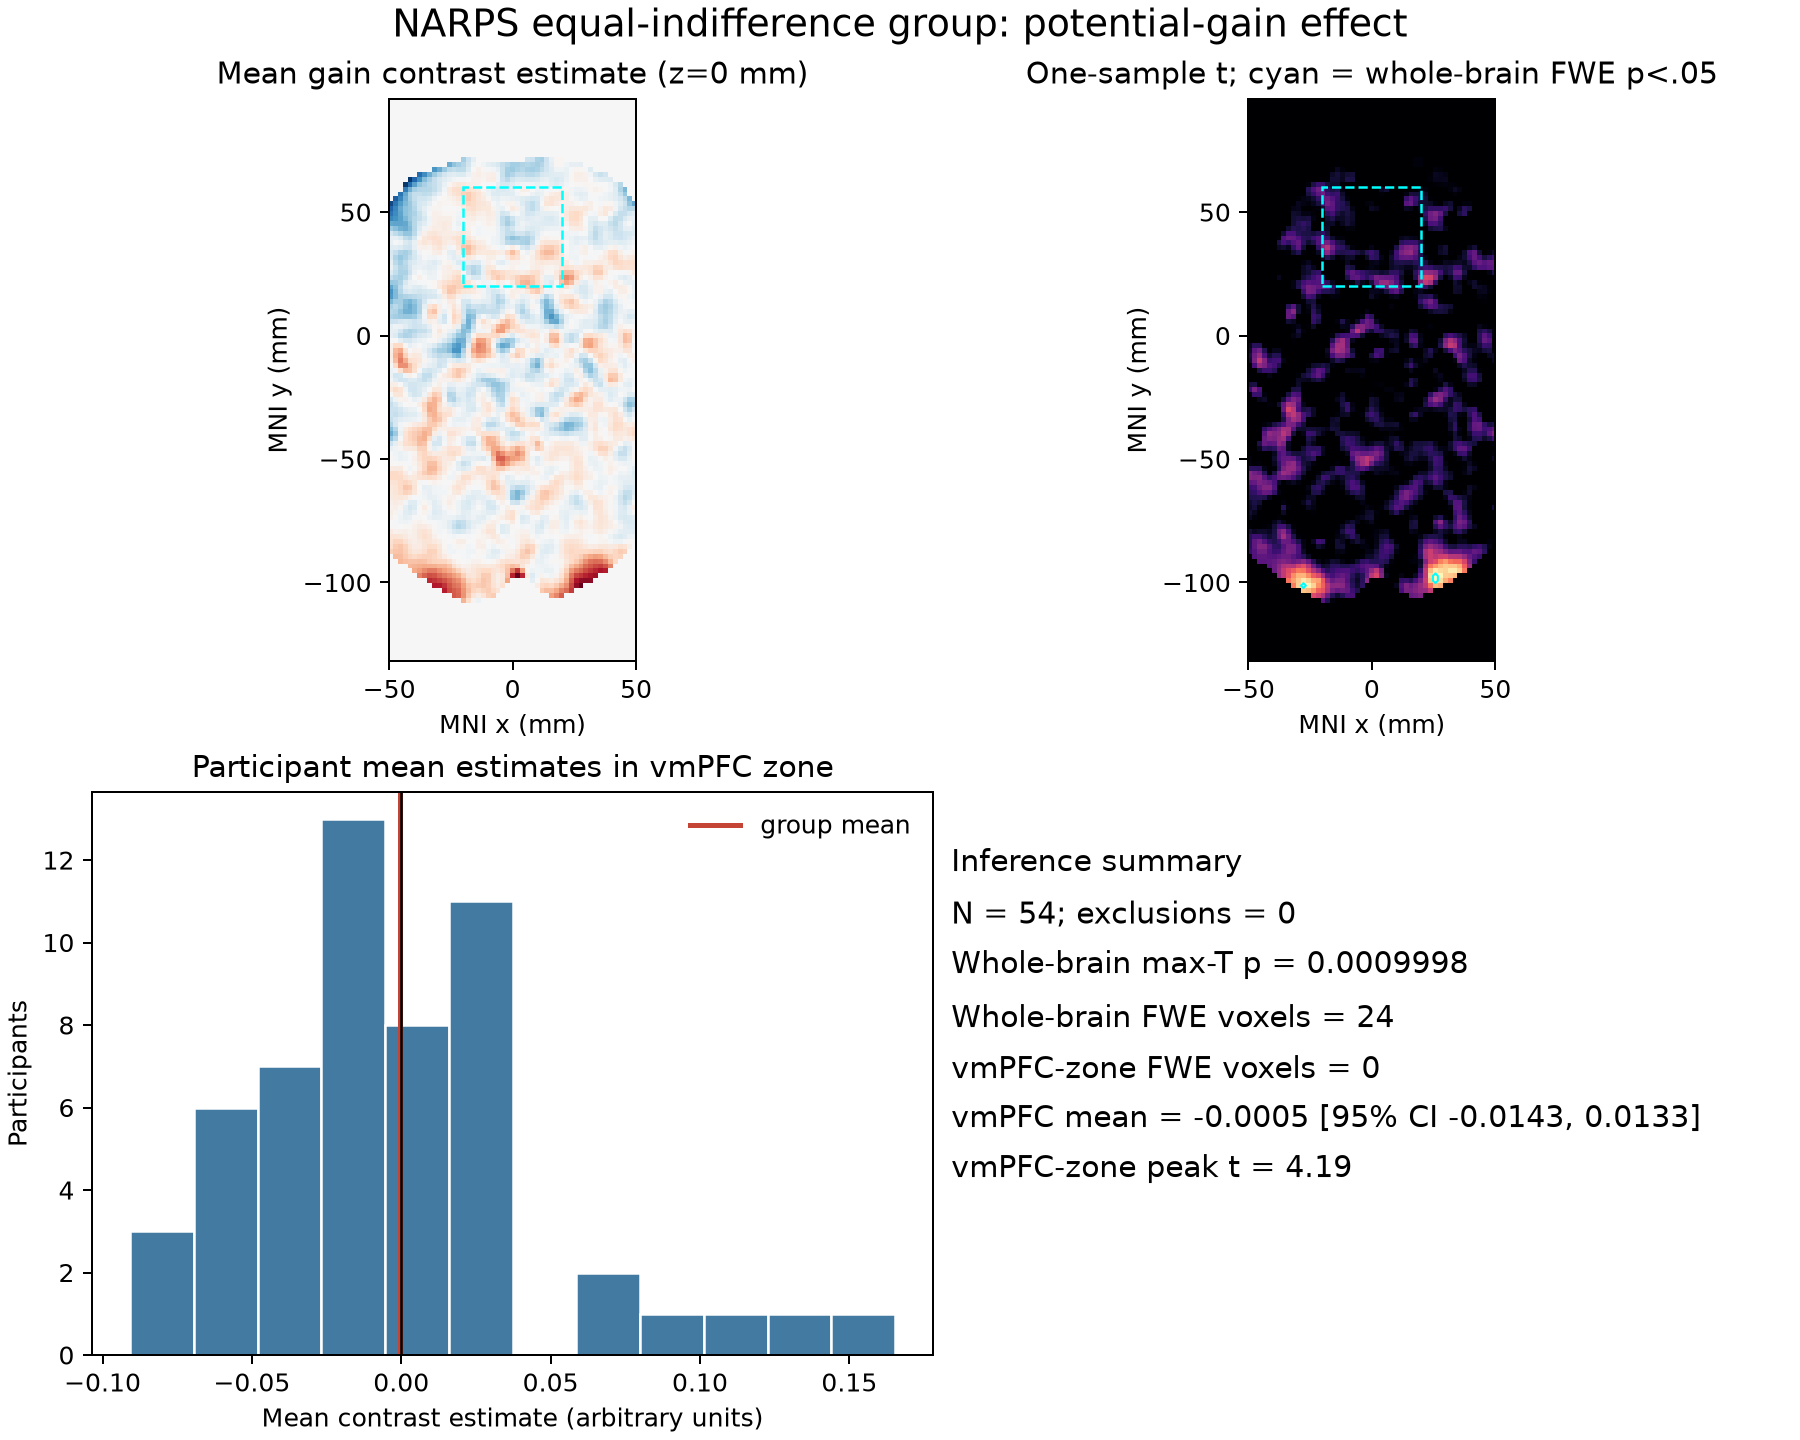

In [4]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "results/figures/group_gain_effect.png")))
